#  Transformer Model Fine-Tuning for Duplicate Question Detection

## Objective

Build and fine-tune a **DistilBERT** transformer model using Hugging Face Transformers to classify duplicate question pairs from the Quora Duplicate Questions Dataset. This week focuses on:

- Implementing transformer-based architecture for semantic similarity
- Fine-tuning DistilBERT on sentence pair classification
- Comparing performance with Week 2 baseline (TF-IDF + Logistic Regression)
- Evaluating the model using standard NLP metrics
- Creating production-ready inference pipeline
- Saving trained model for future deployment

**Dataset:** Quora Duplicate Questions Dataset (sentence-transformers/quora-duplicates)
**Model:** distilbert-base-uncased
**Framework:** Hugging Face Transformers + PyTorch + Trainer API

## 1. Import Libraries


In [60]:
# Core scientific computing libraries
import numpy as np
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Install Trainer dependency before importing Transformers
import sys
import subprocess
import importlib.metadata

try:
    importlib.metadata.version('accelerate')
except importlib.metadata.PackageNotFoundError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'accelerate>=1.1.0'])

# PyTorch and Transformers
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Hugging Face Transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from datasets import load_dataset, Dataset

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress tokenizer parallelism warnings
import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print("All libraries imported successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Device available: {torch.device('cuda' if torch.cuda.is_available() else 'cpu')}")

All libraries imported successfully
PyTorch version: 2.5.1+cu124
Device available: cuda


## 2. GPU Configuration

In [61]:
# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.cuda.empty_cache()
else:
    print("GPU not available. Training will use CPU (significantly slower).")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("GPU configuration complete")

Device: cuda
GPU Name: NVIDIA GeForce RTX 3050 Laptop GPU
GPU Memory: 4.29 GB
GPU configuration complete


In [62]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.5.1+cu124
True
NVIDIA GeForce RTX 3050 Laptop GPU


In [63]:
# Create output directories
PROJECT_ROOT = Path.cwd()

# Always go up to project root (duplicate-question-nlp/)
# regardless of whether notebooks/data/ exists
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'notebooks' / 'data'   # data is inside notebooks/
TRANSFORMER_RESULTS_DIR = PROJECT_ROOT / 'results' / 'transformer_model'
MODELS_DIR = PROJECT_ROOT / 'models'              # models is outside notebooks/ ✅

TRANSFORMER_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"DATA_DIR     : {DATA_DIR}")
print(f"MODELS_DIR   : {MODELS_DIR}")
print(f"Data exists  : {DATA_DIR.exists()}")
print(f"Models exists: {MODELS_DIR.exists()}")

PROJECT_ROOT : d:\NLP\duplicate-question-nlp\duplicate-question-nlp
DATA_DIR     : d:\NLP\duplicate-question-nlp\duplicate-question-nlp\notebooks\data
MODELS_DIR   : d:\NLP\duplicate-question-nlp\duplicate-question-nlp\models
Data exists  : True
Models exists: True


## 2a. Caching Control (skip re-training if a model is already saved)

This cell checks whether a fine-tuned model already exists in `models/saved_transformer_model`.

- If found, the notebook will **load that model instead of training again**, so you can edit/run later cells (evaluation, inference, plots) without waiting through training each time.
- Set `RETRAIN_MODEL = True` below whenever you actually change something that affects training (data, model config, hyperparameters, etc.) and want a fresh run.


In [ ]:
# ============================================================
# CACHING CONTROL
# ============================================================
# RETRAIN_MODEL = False -> reuse a previously saved model if one exists
#                          (skips the slow fine-tuning step entirely)
# RETRAIN_MODEL = True  -> always retrain from scratch, ignoring any
#                          previously saved model
RETRAIN_MODEL = False

SAVED_MODEL_DIR = MODELS_DIR / 'saved_transformer_model'

# A saved model is only usable if the key files actually exist
_has_saved_model = SAVED_MODEL_DIR.exists() and (SAVED_MODEL_DIR / 'config.json').exists()

MODEL_ALREADY_TRAINED = (not RETRAIN_MODEL) and _has_saved_model

if MODEL_ALREADY_TRAINED:
    print(f"Found a saved model at: {SAVED_MODEL_DIR}")
    print("This run will LOAD it and SKIP training/tokenizer-from-scratch loading.")
    print("(Set RETRAIN_MODEL = True above and re-run this cell to force retraining.)")
else:
    if RETRAIN_MODEL:
        print("RETRAIN_MODEL = True -> training from scratch as requested.")
    else:
        print(f"No saved model found at {SAVED_MODEL_DIR} -> training from scratch.")


RETRAIN_MODEL = True -> training from scratch as requested.


## 3. Load Preprocessed Dataset

In [65]:
# Load cleaned Quora dataset from parquet
print("Loading cleaned Quora Duplicate Questions dataset from parquet...")
df = pd.read_parquet(DATA_DIR / 'cleaned_quora.parquet')

# Split into 80% training and 20% test
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])

# Rename columns to match expected format (questions -> [q1, q2], is_duplicate -> label)
train_df = train_df.rename(columns={'clean_q1': 'q1', 'clean_q2': 'q2', 'label': 'is_duplicate'})
test_df = test_df.rename(columns={'clean_q1': 'q1', 'clean_q2': 'q2', 'label': 'is_duplicate'})

# Keep only necessary columns
train_df = train_df[['q1', 'q2', 'is_duplicate']]
test_df = test_df[['q1', 'q2', 'is_duplicate']]

print(f"\nDataset Information:")
print(f"Training set size: {len(train_df):,} pairs")
print(f"Test set size: {len(test_df):,} pairs")
print(f"\nColumn names: {train_df.columns.tolist()}")
print(f"\nFirst 3 samples:")
print(train_df.head(3))

# Check class distribution
print(f"\nClass Distribution (Training Set):")
print(train_df['is_duplicate'].value_counts())
print(f"\nClass Distribution (Test Set):")
print(test_df['is_duplicate'].value_counts())

# Check for missing values
print(f"\nMissing values in training set:")
print(train_df.isnull().sum())
print(f"\nMissing values in test set:")
print(test_df.isnull().sum())

Loading cleaned Quora Duplicate Questions dataset from parquet...

Dataset Information:
Training set size: 323,432 pairs
Test set size: 80,858 pairs

Column names: ['q1', 'q2', 'is_duplicate']

First 3 samples:
                                                       q1  \
341317                                 what is an anagram   
237560  social media what does it mean when a guy dele...   
280719             is this a good time to buy apple stock   

                                                       q2  is_duplicate  
341317                    is there an anagram for anagram             0  
237560  my boyfriend treasures memories he had with hi...             0  
280719         is it a good time to buy apple stock at 92             0  

Class Distribution (Training Set):
is_duplicate
0    204022
1    119410
Name: count, dtype: int64

Class Distribution (Test Set):
is_duplicate
0    51005
1    29853
Name: count, dtype: int64

Missing values in training set:
q1              0
q2   

## 4. Transformer Architecture Selection

In [66]:
# Model Configuration
MODEL_NAME = 'distilbert-base-uncased'
MAX_LENGTH = 128  # Maximum sequence length for tokenization
BATCH_SIZE = 8
LEARNING_RATE = 2e-5
NUM_EPOCHS = 3
WARMUP_STEPS = 500
 
 
print(f"Model Configuration:")
print(f"  Model: {MODEL_NAME}")
print(f"  Max Sequence Length: {MAX_LENGTH}")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Learning Rate: {LEARNING_RATE}")
print(f"  Number of Epochs: {NUM_EPOCHS}")
print(f"  Warmup Steps: {WARMUP_STEPS}")
print(f"  Device: {device}")

# Why DistilBERT?
print(f"\nWhy DistilBERT?")
print("  - 40% smaller than BERT, 60% faster inference")
print("  - Retains 97% of BERT's language understanding capabilities")
print("  - Efficient for production deployment")
print("  - Ideal for computational constraint environments")
print("  - Pre-trained on English corpus with bidirectional context")

Model Configuration:
  Model: distilbert-base-uncased
  Max Sequence Length: 128
  Batch Size: 8
  Learning Rate: 2e-05
  Number of Epochs: 3
  Warmup Steps: 500
  Device: cuda

Why DistilBERT?
  - 40% smaller than BERT, 60% faster inference
  - Retains 97% of BERT's language understanding capabilities
  - Efficient for production deployment
  - Ideal for computational constraint environments
  - Pre-trained on English corpus with bidirectional context


## 5. Tokenization for Sentence Pair Classification

In [67]:
# Load tokenizer
if MODEL_ALREADY_TRAINED:
    print(f"Loading tokenizer from saved model: {SAVED_MODEL_DIR}...")
    tokenizer = AutoTokenizer.from_pretrained(SAVED_MODEL_DIR)
else:
    print(f"Loading tokenizer for {MODEL_NAME}...")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"\nTokenizer Information:")
print(f"  Vocabulary size: {tokenizer.vocab_size:,}")
print(f"  Special tokens: {tokenizer.special_tokens_map}")

# Example tokenization for sentence pair
example_question1 = "What is machine learning?"
example_question2 = "What is artificial intelligence?"

print(f"\nExample Tokenization (Sentence Pair):")
print(f"Question 1: {example_question1}")
print(f"Question 2: {example_question2}")

example_tokens = tokenizer(
    example_question1,
    example_question2,
    max_length=MAX_LENGTH,
    padding='max_length',
    truncation=True,
    return_tensors='pt'
)

print(f"\nTokenized output shape: {example_tokens['input_ids'].shape}")
print(f"Input IDs (first 20): {example_tokens['input_ids'][0][:20].tolist()}")
print(f"Attention Mask (first 20): {example_tokens['attention_mask'][0][:20].tolist()}")


Loading tokenizer for distilbert-base-uncased...

Tokenizer Information:
  Vocabulary size: 30,522
  Special tokens: {'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}

Example Tokenization (Sentence Pair):
Question 1: What is machine learning?
Question 2: What is artificial intelligence?

Tokenized output shape: torch.Size([1, 128])
Input IDs (first 20): [101, 2054, 2003, 3698, 4083, 1029, 102, 2054, 2003, 7976, 4454, 1029, 102, 0, 0, 0, 0, 0, 0, 0]
Attention Mask (first 20): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]


## 6. Dataset Encoding Pipeline

In [68]:
# Convert pandas DataFrames to Hugging Face Dataset format
from datasets import Dataset

print("Converting to Hugging Face Dataset format...")
train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

# Tokenization function for dataset (updated for parquet columns)
def tokenize_function(examples):
    """
    Tokenize sentence pairs for DistilBERT.
    Handles maximum sequence length and padding.
    """
    return tokenizer(
        examples['q1'],  # First question (cleaned)
        examples['q2'],  # Second question (cleaned)
        max_length=MAX_LENGTH,
        padding='max_length',
        truncation=True,
    )

# Prepare datasets
print("Encoding training dataset...")
train_dataset_encoded = train_dataset.map(
    tokenize_function,
    batched=True,
    batch_size=1000,
    remove_columns=['q1', 'q2'],
    desc="Tokenizing training data"
)

print("Encoding test dataset...")
test_dataset_encoded = test_dataset.map(
    tokenize_function,
    batched=True,
    batch_size=1000,
    remove_columns=['q1', 'q2'],
    desc="Tokenizing test data"
)

# Rename 'is_duplicate' to 'labels' for Trainer API
train_dataset_encoded = train_dataset_encoded.rename_column('is_duplicate', 'labels')
test_dataset_encoded = test_dataset_encoded.rename_column('is_duplicate', 'labels')

# Set data format for PyTorch
train_dataset_encoded.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
test_dataset_encoded.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

print(f"\nEncoded Dataset Information:")
print(f"Training set: {len(train_dataset_encoded)} samples")
print(f"Test set: {len(test_dataset_encoded)} samples")
print(f"\nSample encoded data:")
print(train_dataset_encoded[0])

Converting to Hugging Face Dataset format...
Encoding training dataset...


Tokenizing training data:   0%|          | 0/323432 [00:00<?, ? examples/s]

Encoding test dataset...


Tokenizing test data:   0%|          | 0/80858 [00:00<?, ? examples/s]


Encoded Dataset Information:
Training set: 323432 samples
Test set: 80858 samples

Sample encoded data:
{'labels': tensor(0), 'input_ids': tensor([  101,  2054,  2003,  2019,  9617, 13113,   102,  2003,  2045,  2019,
         9617, 13113,  2005,  9617, 13113,   102,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
  

## 7. Train Validation Test Split

Creating train-validation split...

Data Split Summary:
Training set: 291,088 samples
Validation set: 32,344 samples
Test set: 80,858 samples
Total: 404,290 samples

Class Distribution:
Training - Duplicates: 107,457, Non-duplicates: 183,631
Validation - Duplicates: 11,953, Non-duplicates: 20,391
Test - Duplicates: 29,853, Non-duplicates: 51,005


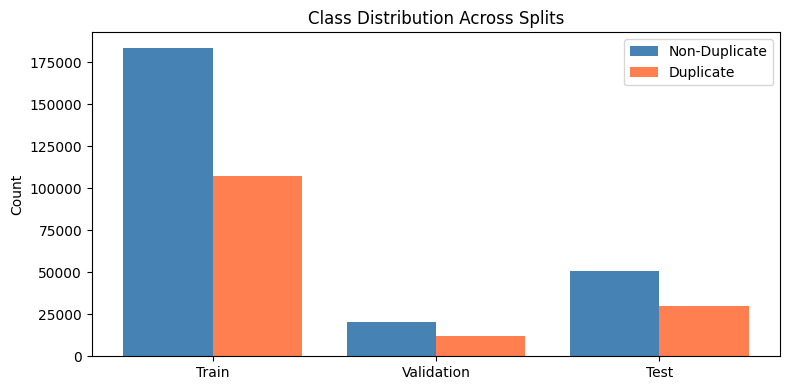

Saved: d:\NLP\duplicate-question-nlp\duplicate-question-nlp\results\transformer_model\split_class_distribution.png


In [69]:
# Split training data into train and validation (90-10 split)
print(f"Creating train-validation split...")
validation_fraction = 0.1
train_val_split = train_dataset_encoded.train_test_split(test_size=validation_fraction, seed=42)

train_dataset_final = train_val_split['train']
validation_dataset = train_val_split['test']

print(f"\nData Split Summary:")
print(f"Training set: {len(train_dataset_final):,} samples")
print(f"Validation set: {len(validation_dataset):,} samples")
print(f"Test set: {len(test_dataset_encoded):,} samples")
print(f"Total: {len(train_dataset_final) + len(validation_dataset) + len(test_dataset_encoded):,} samples")

# Class distribution in each split
train_labels = np.array(train_dataset_final['labels'])
val_labels = np.array(validation_dataset['labels'])
test_labels = np.array(test_dataset_encoded['labels'])

print(f"\nClass Distribution:")
print(f"Training - Duplicates: {(train_labels == 1).sum():,}, Non-duplicates: {(train_labels == 0).sum():,}")
print(f"Validation - Duplicates: {(val_labels == 1).sum():,}, Non-duplicates: {(val_labels == 0).sum():,}")
print(f"Test - Duplicates: {(test_labels == 1).sum():,}, Non-duplicates: {(test_labels == 0).sum():,}")
# Visualize class distribution across splits
fig, ax = plt.subplots(figsize=(8, 4))
split_names = ['Train', 'Validation', 'Test']
dup_counts = [(train_labels == 1).sum(), (val_labels == 1).sum(), (test_labels == 1).sum()]
non_dup_counts = [(train_labels == 0).sum(), (val_labels == 0).sum(), (test_labels == 0).sum()]
x = np.arange(len(split_names))
ax.bar(x - 0.2, non_dup_counts, 0.4, label='Non-Duplicate', color='steelblue')
ax.bar(x + 0.2, dup_counts, 0.4, label='Duplicate', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(split_names)
ax.set_title('Class Distribution Across Splits')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.savefig(TRANSFORMER_RESULTS_DIR / 'split_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {TRANSFORMER_RESULTS_DIR / 'split_class_distribution.png'}")


In [70]:
from pathlib import Path

def print_tree(path, indent=0, max_depth=4):
    p = Path(path)
    if indent > max_depth:
        return
    print('  ' * indent + p.name + ('/' if p.is_dir() else f'  ({p.stat().st_size/1e6:.1f} MB)'))
    if p.is_dir():
        for child in sorted(p.iterdir()):
            print_tree(child, indent+1, max_depth)

print_tree('.')  # or your PROJECT_ROOT path

/
  baseline_model_new.ipynb  (0.0 MB)
  baseline_model_new_fixed.ipynb  (0.2 MB)
  data/
    cleaned_quora.parquet  (86.6 MB)
    raw_quora_dedup.parquet  (32.7 MB)
  data_analysis_new.ipynb  (0.2 MB)
  requirements.txt  (0.0 MB)
  results/
    baseline_model/
      week2_error_distribution.png  (0.0 MB)
      week2_error_examples.parquet  (1.4 MB)
      week2_model_comparison.parquet  (0.0 MB)
      week2_model_comparison.png  (0.1 MB)
    data_analysis/
    transformer_model/
      split_class_distribution.png  (0.0 MB)
  transformer_model.ipynb  (0.1 MB)
  transformer_model_new.ipynb  (0.1 MB)


## 8. Model Initialization

In [71]:
# Load model: reuse the saved fine-tuned model if available, otherwise
# start from the base pretrained checkpoint
if MODEL_ALREADY_TRAINED:
    print(f"Loading previously fine-tuned model from: {SAVED_MODEL_DIR}...")
    model = AutoModelForSequenceClassification.from_pretrained(
        SAVED_MODEL_DIR,
        num_labels=2
    )
else:
    print(f"Loading pre-trained model: {MODEL_NAME}...")
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2  # Binary classification: 0=non-duplicate, 1=duplicate
    )

# Move model to device
model = model.to(device)

print(f"\nModel Architecture:")
print(model)

# Model parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable_params = total_params - trainable_params

print(f"\nModel Size:")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Non-trainable parameters: {non_trainable_params:,}")


Loading pre-trained model: distilbert-base-uncased...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model Architecture:
DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p

## 9. Evaluation Metrics

In [72]:
# Install Hugging Face evaluate if it is missing
import sys
import subprocess

try:
    import evaluate
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'evaluate'])
    import evaluate

print('evaluate is ready')

evaluate is ready


In [73]:
# Import evaluation metrics from Hugging Face
import evaluate

# Load metrics
accuracy_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    """
    Compute evaluation metrics for model validation and testing.
    
    Metrics:
    - Accuracy: Overall correctness
    - F1 Score: Harmonic mean of precision and recall
    - Precision: Correctness of positive predictions
    - Recall: Coverage of positive instances
    - ROC-AUC: Area under the ROC curve
    """
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    
    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)['accuracy']
    f1 = f1_metric.compute(predictions=predictions, references=labels, average='weighted')['f1']
    
    try:
        from scipy.special import softmax as scipy_softmax
        probs = scipy_softmax(logits, axis=1)[:, 1]
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = 0.0
    
    return {
        'accuracy': accuracy,
        'f1': f1,
        'precision': precision_score(labels, predictions, average='weighted', zero_division=0),
        'recall': recall_score(labels, predictions, average='weighted', zero_division=0),
        'roc_auc': auc,
    }

print('Evaluation metrics configured')
print(f'\\nMetrics to be computed:')
print(f'  - Accuracy: Proportion of correct predictions')
print(f'  - Precision: True positives / (True positives + False positives)')
print(f'  - Recall: True positives / (True positives + False negatives)')
print(f'  - F1 Score: Harmonic mean of precision and recall')

Evaluation metrics configured
\nMetrics to be computed:
  - Accuracy: Proportion of correct predictions
  - Precision: True positives / (True positives + False positives)
  - Recall: True positives / (True positives + False negatives)
  - F1 Score: Harmonic mean of precision and recall


### Why Use Evaluation Metrics?

Evaluation metrics help assess model performance beyond just accuracy. They provide different perspectives on how well the model makes predictions.

**Key Reasons:**
1. **Accuracy alone is misleading** - With imbalanced datasets, high accuracy doesn't mean good predictions
2. **Business implications** - Different mistakes have different costs
3. **Model comparison** - Metrics help compare different models objectively
4. **Identify bias** - Metrics show if model performs better on one class than another

**Our 4 Metrics Explained:**

| Metric | Formula | What it Measures | When to Use |
|--------|---------|------------------|------------|
| **Accuracy** | (TP+TN)/(TP+TN+FP+FN) | Overall correctness | Balanced datasets |
| **Precision** | TP/(TP+FP) | Of predicted duplicates, how many are actually duplicates? | When False Positives are costly |
| **Recall** | TP/(TP+FN) | Of actual duplicates, how many did we find? | When False Negatives are costly |
| **F1 Score** | 2*(Precision*Recall)/(Precision+Recall) | Harmonic mean balancing precision and recall | Best overall metric for imbalanced data |

**For Duplicate Question Detection:**
- **High Recall** = Find most duplicate questions (don't miss duplicates)
- **High Precision** = Avoid false alarms (don't flag non-duplicates as duplicates)
- **F1 Score** = Best balance between the two

## 10. Training Configuration

In [74]:
# Create training arguments
import inspect
import sys
import importlib.metadata
print(f"Python executable: {sys.executable}")
print(f"Transformers version: {importlib.metadata.version('transformers')}")
print(f"Accelerate version: {importlib.metadata.version('accelerate')}")
print(f"Torch version: {torch.__version__}")

output_dir = MODELS_DIR / 'transformer_training_outputs'
Path(output_dir).mkdir(parents=True, exist_ok=True)

base_training_args = {
    'output_dir': output_dir,
    'num_train_epochs': NUM_EPOCHS,
    'per_device_train_batch_size': BATCH_SIZE,
    'per_device_eval_batch_size': BATCH_SIZE,
    'warmup_steps': WARMUP_STEPS,
    'weight_decay': 0.01,
    'learning_rate': LEARNING_RATE,
    'logging_steps': 100,
    'save_strategy': 'epoch',
    'load_best_model_at_end': True,
    'metric_for_best_model': 'f1',
    'greater_is_better': True,
    'save_total_limit': 1,         # keep only best checkpoint
    'save_only_model': True,       # skip optimizer.pt (~500MB saved per checkpoint)
    'fp16': torch.cuda.is_available(),
    'gradient_accumulation_steps': 2,
    'seed': 42,
    'report_to': [],
}

training_arg_names = set(inspect.signature(TrainingArguments.__init__).parameters)
if 'evaluation_strategy' in training_arg_names:
    base_training_args['evaluation_strategy'] = 'epoch'
elif 'eval_strategy' in training_arg_names:
    base_training_args['eval_strategy'] = 'epoch'

supported_training_args = {
    key: value
    for key, value in base_training_args.items()
    if key in training_arg_names
}

ignored_args = sorted(set(base_training_args) - set(supported_training_args))
if ignored_args:
    print(f'Ignoring unsupported TrainingArguments for this environment: {ignored_args}')

try:
    training_args = TrainingArguments(**supported_training_args)
except ImportError as exc:
    if "accelerate" in str(exc):
        raise RuntimeError(
            "Accelerate is installed, but this notebook kernel loaded Transformers before it was available. "
            "Restart the kernel, then run the notebook from the top."
        ) from exc
    raise

print("Training Arguments:")
print(f"  Output directory: {output_dir}")
print(f"  Number of epochs: {NUM_EPOCHS}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Warmup steps: {WARMUP_STEPS}")
print("  Weight decay: 0.01")
print("  Evaluation strategy: epoch")
print(f"  FP16 (mixed precision): {torch.cuda.is_available()}")
print("  Gradient accumulation steps: 2")
print("  Save total limit: 1")
print("  Save only model: True")

Python executable: d:\NLP\venv\Scripts\python.exe
Transformers version: 5.11.0
Accelerate version: 1.14.0
Torch version: 2.5.1+cu124
Training Arguments:
  Output directory: d:\NLP\duplicate-question-nlp\duplicate-question-nlp\models\transformer_training_outputs
  Number of epochs: 3
  Batch size: 8
  Learning rate: 2e-05
  Warmup steps: 500
  Weight decay: 0.01
  Evaluation strategy: epoch
  FP16 (mixed precision): True
  Gradient accumulation steps: 2
  Save total limit: 1
  Save only model: True


## 11. Transformer Fine-Tuning

In [ ]:
# Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset_final,
    eval_dataset=validation_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2, early_stopping_threshold=0.0)],
)

if MODEL_ALREADY_TRAINED:
    print("MODEL_ALREADY_TRAINED = True -> skipping trainer.train().")
    print(f"Using the model already loaded from {SAVED_MODEL_DIR}.")
    train_result = None
else:
    print("Starting transformer fine-tuning...")
    print(f"Training on {device}")
    print(f"Total training steps: {len(train_dataset_final) // BATCH_SIZE * NUM_EPOCHS}")
    print("\n" + "="*80)

    # Train the model
    train_result = trainer.train(resume_from_checkpoint=True )

    print("\n" + "="*80)
    print("Training completed!")
    print(f"\nTraining Results:")
    print(f"  Final training loss: {train_result.training_loss:.4f}")
    print(f"  Total training time: {train_result.metrics.get('train_runtime', 0):.2f} seconds")


Starting transformer fine-tuning...
Training on cuda
Total training steps: 109158



Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall,Roc Auc
1,0.624124,0.290641,0.875093,0.874153,0.874321,0.875093,0.949567
2,0.422466,0.293171,0.890953,0.891330,0.892024,0.890953,0.957235
3,0.383886,0.374943,0.895158,0.895621,0.896624,0.895158,0.958160


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed!

Training Results:
  Final training loss: 0.5004
  Total training time: 6788.57 seconds


## 12. Model Evaluation

In [76]:
# Evaluate on validation set
print("Evaluating on validation set...")
val_results = trainer.evaluate()
print(f"\nValidation Metrics:")
for key, value in val_results.items():
    if not key.startswith('eval_runtime'):
        print(f"  {key}: {value:.4f}")

# Evaluate on test set
print("\nEvaluating on test set...")
test_results = trainer.evaluate(eval_dataset=test_dataset_encoded)
print(f"\nTest Set Metrics:")
for key, value in test_results.items():
    if not key.startswith('eval_runtime'):
        print(f"  {key}: {value:.4f}")

# Get predictions on test set
print("\nGenerating predictions on test set...")
predictions = trainer.predict(test_dataset_encoded)
pred_labels = np.argmax(predictions.predictions, axis=1)
true_labels = test_dataset_encoded['labels']

# Detailed classification report
print("\nDetailed Classification Report (Test Set):")
print(classification_report(
    true_labels,
    pred_labels,
    target_names=['Non-Duplicate', 'Duplicate'],
    digits=4
))

# Confusion matrix
cm = confusion_matrix(true_labels, pred_labels)
print(f"\nConfusion Matrix:")
print(f"  [[TN={cm[0,0]:6d}  FP={cm[0,1]:6d}]")
print(f"   [FN={cm[1,0]:6d}  TP={cm[1,1]:6d}]]")

Evaluating on validation set...


Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall,Roc Auc
0.383886,0.374943,3,0.895158,0.895621,0.896624,0.895158,0.958160



Validation Metrics:
  eval_loss: 0.3749
  eval_accuracy: 0.8952
  eval_f1: 0.8956
  eval_precision: 0.8966
  eval_recall: 0.8952
  eval_roc_auc: 0.9582

Evaluating on test set...


Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall,Roc Auc
0.383886,0.368246,3,0.896300,0.896728,0.897619,0.896300,0.958859



Test Set Metrics:
  eval_loss: 0.3682
  eval_accuracy: 0.8963
  eval_f1: 0.8967
  eval_precision: 0.8976
  eval_recall: 0.8963
  eval_roc_auc: 0.9589

Generating predictions on test set...



Detailed Classification Report (Test Set):
               precision    recall  f1-score   support

Non-Duplicate     0.9285    0.9053    0.9168     51005
    Duplicate     0.8448    0.8809    0.8625     29853

     accuracy                         0.8963     80858
    macro avg     0.8867    0.8931    0.8896     80858
 weighted avg     0.8976    0.8963    0.8967     80858


Confusion Matrix:
  [[TN= 46175  FP=  4830]
   [FN=  3555  TP= 26298]]


## 13. Training Visualization

Training visualization saved to d:\NLP\duplicate-question-nlp\duplicate-question-nlp\results\transformer_model\transformer_training_visualization.png


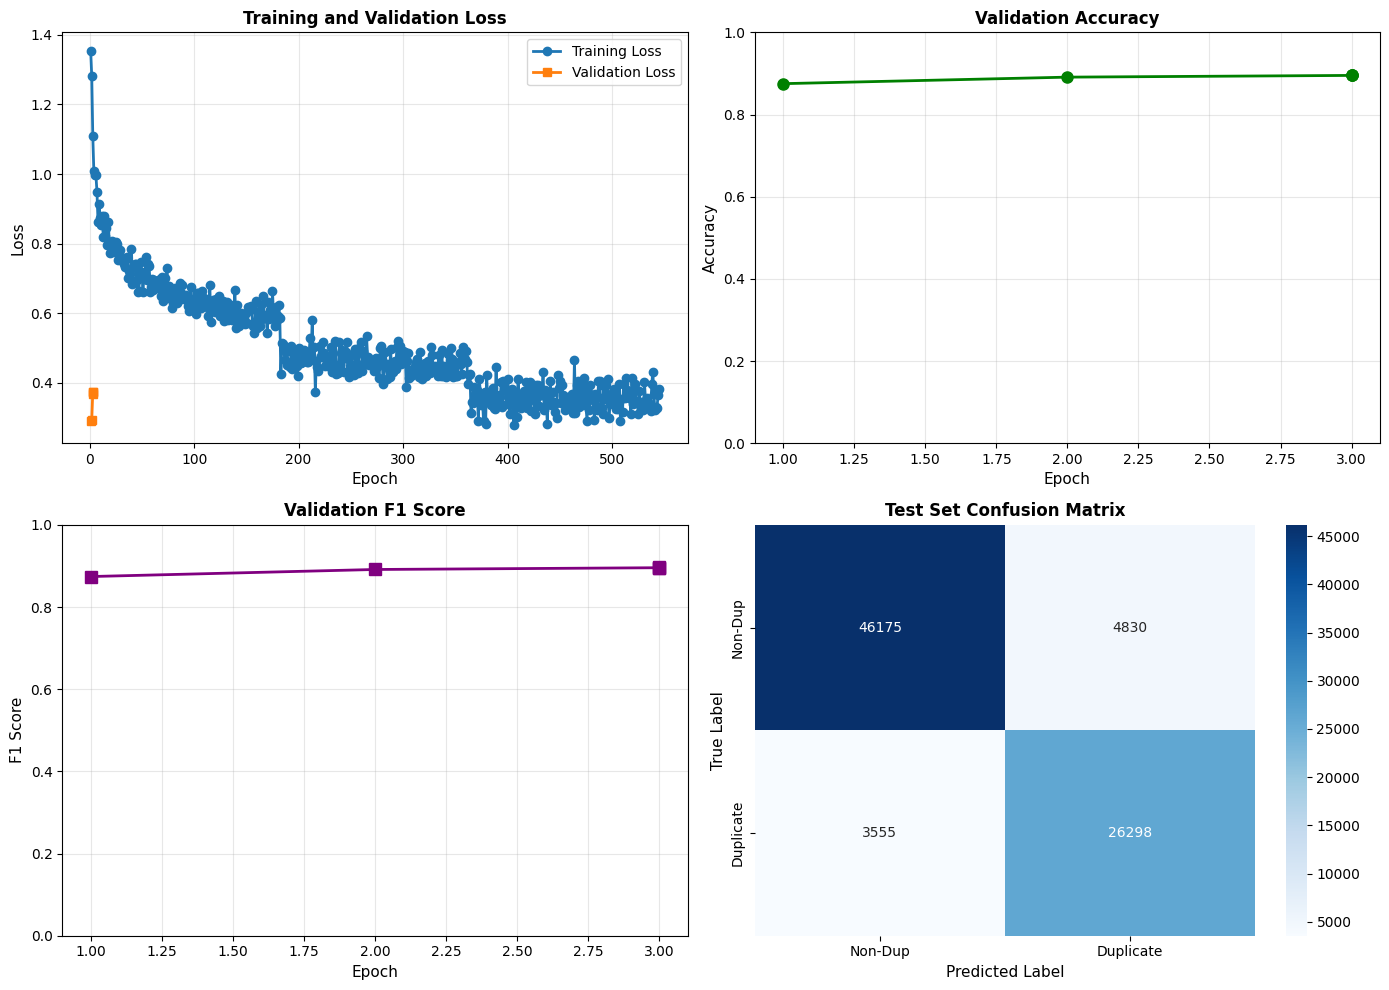

In [77]:
# Extract training history
training_logs = trainer.state.log_history

# Parse logs into epochs
epochs = []
train_losses = []
val_losses = []
val_accuracies = []
val_f1_scores = []

for log in training_logs:
    if 'epoch' in log:
        if 'loss' in log and 'eval_loss' not in log:
            train_losses.append(log['loss'])
        if 'eval_loss' in log:
            epochs.append(log['epoch'])
            val_losses.append(log['eval_loss'])
            val_accuracies.append(log.get('eval_accuracy', 0))
            val_f1_scores.append(log.get('eval_f1', 0))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss plot
if train_losses and val_losses:
    axes[0, 0].plot(range(1, len(train_losses) + 1), train_losses, 'o-', label='Training Loss', linewidth=2)
    axes[0, 0].plot(epochs, val_losses, 's-', label='Validation Loss', linewidth=2)
    axes[0, 0].set_xlabel('Epoch', fontsize=11)
    axes[0, 0].set_ylabel('Loss', fontsize=11)
    axes[0, 0].set_title('Training and Validation Loss', fontsize=12, fontweight='bold')
    axes[0, 0].legend(fontsize=10)
    axes[0, 0].grid(True, alpha=0.3)

# Accuracy plot
if val_accuracies:
    axes[0, 1].plot(epochs, val_accuracies, 'o-', color='green', linewidth=2, markersize=8)
    axes[0, 1].set_xlabel('Epoch', fontsize=11)
    axes[0, 1].set_ylabel('Accuracy', fontsize=11)
    axes[0, 1].set_title('Validation Accuracy', fontsize=12, fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].set_ylim([0, 1])

# F1 Score plot
if val_f1_scores:
    axes[1, 0].plot(epochs, val_f1_scores, 's-', color='purple', linewidth=2, markersize=8)
    axes[1, 0].set_xlabel('Epoch', fontsize=11)
    axes[1, 0].set_ylabel('F1 Score', fontsize=11)
    axes[1, 0].set_title('Validation F1 Score', fontsize=12, fontweight='bold')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].set_ylim([0, 1])

# Confusion matrix heatmap
cm = confusion_matrix(true_labels, pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1, 1],
            xticklabels=['Non-Dup', 'Duplicate'],
            yticklabels=['Non-Dup', 'Duplicate'])
axes[1, 1].set_ylabel('True Label', fontsize=11)
axes[1, 1].set_xlabel('Predicted Label', fontsize=11)
axes[1, 1].set_title('Test Set Confusion Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(TRANSFORMER_RESULTS_DIR / 'transformer_training_visualization.png', dpi=300, bbox_inches='tight')
print(f"Training visualization saved to {TRANSFORMER_RESULTS_DIR / 'transformer_training_visualization.png'}")
plt.show()

## 14. Prediction Examples and Error Analysis

In [78]:
# Function for making predictions on new text
def predict_duplicate(question1, question2):
    """
    Predict if two questions are duplicates.
    
    Args:
        question1: First question string
        question2: Second question string
    
    Returns:
        Dictionary with prediction and confidence
    """
    # Tokenize
    inputs = tokenizer(
        question1,
        question2,
        max_length=MAX_LENGTH,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    )
    
    # Move to device
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    # Get model prediction
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
    
    # Apply softmax for probabilities
    probs = torch.softmax(logits, dim=1)[0]
    predicted_class = torch.argmax(probs).item()
    confidence = probs[predicted_class].item()
    
    return {
        'question1': question1,
        'question2': question2,
        'prediction': 'Duplicate' if predicted_class == 1 else 'Non-Duplicate',
        'confidence': confidence,
        'is_duplicate': predicted_class
    }

# Test on sample predictions
print("Sample Predictions:")
print("="*100)

test_cases = [
    ("What is machine learning?", "What is artificial intelligence?"),
    ("How do I learn Python?", "How to learn Python programming?"),
    ("What is the capital of France?", "What is the largest city in France?"),
    ("How to make pasta?", "How to cook pizza?"),
    ("What is deep learning?", "What is neural networks?"),
]

predictions_list = []
for q1, q2 in test_cases:
    result = predict_duplicate(q1, q2)
    predictions_list.append(result)
    print(f"\nQ1: {q1}")
    print(f"Q2: {q2}")
    print(f"Prediction: {result['prediction']} (Confidence: {result['confidence']:.4f})")
    print("-"*100)

# ── Real Error Analysis ──
print("\n" + "="*100)
print("ERROR ANALYSIS")
print("="*100)

# Build a DataFrame with original questions for display
error_analysis_df = pd.DataFrame({
    'true_label': true_labels,
    'predicted_label': pred_labels,
    'q1': test_df['q1'].values,
    'q2': test_df['q2'].values,
    'confidence_dup': predictions.predictions[:, 1],
})

false_positives = error_analysis_df[
    (error_analysis_df['true_label'] == 0) & (error_analysis_df['predicted_label'] == 1)
].head(5)

false_negatives = error_analysis_df[
    (error_analysis_df['true_label'] == 1) & (error_analysis_df['predicted_label'] == 0)
].head(5)

print(f"\nTotal errors: {len(error_analysis_df[error_analysis_df['true_label'] != error_analysis_df['predicted_label']])}")

print("\n=== FALSE POSITIVES (predicted Duplicate, actually Non-Duplicate) ===")
for _, row in false_positives.iterrows():
    print(f"Q1: {row['q1']}\nQ2: {row['q2']}\nConfidence (dup): {row['confidence_dup']:.4f}\n{'-'*80}")

print("\n=== FALSE NEGATIVES (predicted Non-Duplicate, actually Duplicate) ===")
for _, row in false_negatives.iterrows():
    print(f"Q1: {row['q1']}\nQ2: {row['q2']}\nConfidence (dup): {row['confidence_dup']:.4f}\n{'-'*80}")


Sample Predictions:

Q1: What is machine learning?
Q2: What is artificial intelligence?
Prediction: Non-Duplicate (Confidence: 0.9948)
----------------------------------------------------------------------------------------------------

Q1: How do I learn Python?
Q2: How to learn Python programming?
Prediction: Duplicate (Confidence: 0.9934)
----------------------------------------------------------------------------------------------------

Q1: What is the capital of France?
Q2: What is the largest city in France?
Prediction: Duplicate (Confidence: 0.8306)
----------------------------------------------------------------------------------------------------

Q1: How to make pasta?
Q2: How to cook pizza?
Prediction: Duplicate (Confidence: 0.9464)
----------------------------------------------------------------------------------------------------

Q1: What is deep learning?
Q2: What is neural networks?
Prediction: Non-Duplicate (Confidence: 0.9998)
----------------------------------------

In [91]:
def predict_duplicate(q1, q2):
    inputs = tokenizer(
        q1, q2,
        max_length=MAX_LENGTH,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()
        confidence = probs[0][pred].item()

    label = "Duplicate" if pred == 1 else "Not Duplicate"
    print(f"Q1: {q1}")
    print(f"Q2: {q2}")
    print(f"Prediction  : {label}")
    print(f"Confidence  : {confidence*100:.1f}%")
    print(f"Answer      : These questions are {'DUPLICATES ✅' if pred == 1 else 'NOT DUPLICATES ❌'}")
    print("-" * 60)

# Test all pairs
test_pairs = [
    # True duplicates
    ("How to make pasta?", "What is the recipe for pasta?"),
    ("What is AI?", "Can you explain artificial intelligence?"),
    
    # True non-duplicates  
    ("How to make pasta?", "How to cook pizza?"),
    ("What is Python?", "What is a python snake?"),
    
    # Tricky ones
    ("How to lose weight fast?", "What are quick weight loss tips?"),
]

for q1, q2 in test_pairs:
    predict_duplicate(q1, q2)

Q1: How to make pasta?
Q2: What is the recipe for pasta?
Prediction  : Duplicate
Confidence  : 99.5%
Answer      : These questions are DUPLICATES ✅
------------------------------------------------------------
Q1: What is AI?
Q2: Can you explain artificial intelligence?
Prediction  : Not Duplicate
Confidence  : 99.2%
Answer      : These questions are NOT DUPLICATES ❌
------------------------------------------------------------
Q1: How to make pasta?
Q2: How to cook pizza?
Prediction  : Duplicate
Confidence  : 94.6%
Answer      : These questions are DUPLICATES ✅
------------------------------------------------------------
Q1: What is Python?
Q2: What is a python snake?
Prediction  : Duplicate
Confidence  : 98.5%
Answer      : These questions are DUPLICATES ✅
------------------------------------------------------------
Q1: How to lose weight fast?
Q2: What are quick weight loss tips?
Prediction  : Duplicate
Confidence  : 99.8%
Answer      : These questions are DUPLICATES ✅
---------------

## 15. Comparison with Week 2 Baseline


WEEK 2 vs WEEK 3 PERFORMANCE COMPARISON
                      Method  Accuracy  Precision  Recall  F1 Score
TF-IDF + Logistic Regression    0.7416   0.712800  0.5030  0.591100
        DistilBERT + Trainer    0.8963   0.897619  0.8963  0.896728

IMPROVEMENTS (Week 3 vs Week 2)
Accuracy        +15.47% (Improvement)
Precision       +18.48% (Improvement)
Recall          +39.33% (Improvement)
F1 Score        +30.56% (Improvement)

Comparison visualization saved to d:\NLP\duplicate-question-nlp\duplicate-question-nlp\results\transformer_model\week2_vs_week3_comparison.png


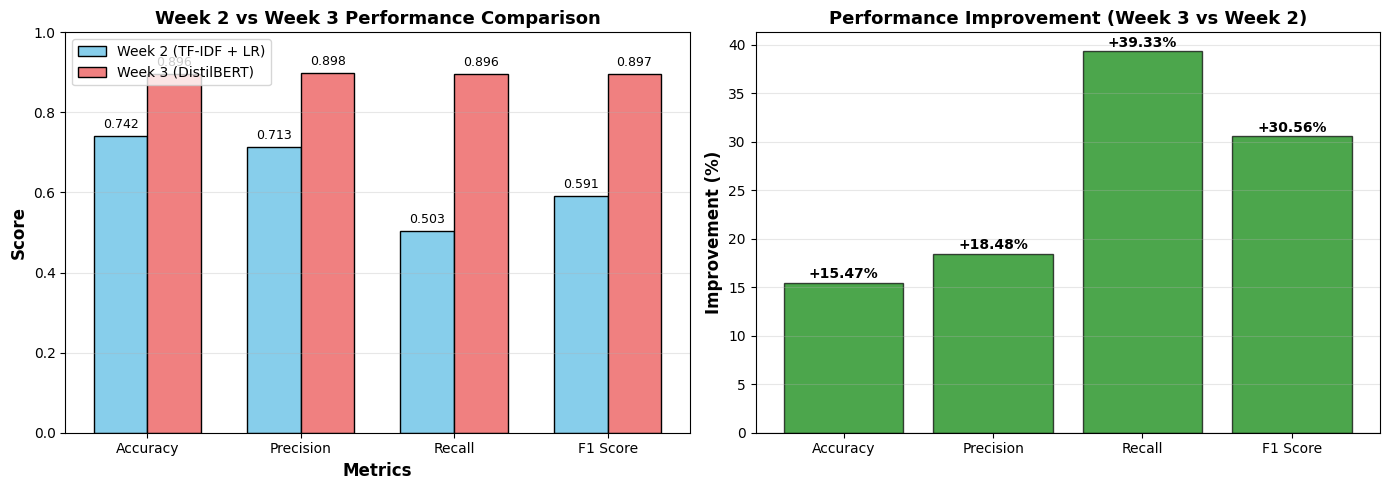

Comparison results saved to d:\NLP\duplicate-question-nlp\duplicate-question-nlp\results\transformer_model\week2_vs_week3_comparison.csv


In [79]:
# Week 2 Baseline Results (from baseline_model.ipynb)
# These are the best results achieved with TF-IDF + Logistic Regression
baseline_results = {
    'Method': 'TF-IDF + Logistic Regression',
    'Accuracy': 0.7416,
    'Precision': 0.7128,
    'Recall': 0.5030,
    'F1 Score': 0.5911,
}

# Week 3 Transformer Results
transformer_results = {
    'Method': 'DistilBERT + Trainer',
    'Accuracy': test_results['eval_accuracy'],
    'Precision': test_results['eval_precision'],
    'Recall': test_results['eval_recall'],
    'F1 Score': test_results['eval_f1'],
}

# Create comparison dataframe
comparison_df = pd.DataFrame([
    baseline_results,
    transformer_results
])

print("\n" + "="*100)
print("WEEK 2 vs WEEK 3 PERFORMANCE COMPARISON")
print("="*100)
print(comparison_df.to_string(index=False))

# Calculate improvements
print("\n" + "="*100)
print("IMPROVEMENTS (Week 3 vs Week 2)")
print("="*100)

improvements = {
    'Accuracy': (transformer_results['Accuracy'] - baseline_results['Accuracy']) * 100,
    'Precision': (transformer_results['Precision'] - baseline_results['Precision']) * 100,
    'Recall': (transformer_results['Recall'] - baseline_results['Recall']) * 100,
    'F1 Score': (transformer_results['F1 Score'] - baseline_results['F1 Score']) * 100,
}

for metric, improvement in improvements.items():
    direction = "Improvement" if improvement > 0 else "Decline"
    print(f"{metric:15} {improvement:+.2f}% ({direction})")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Metrics comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
baseline_vals = [baseline_results[m] for m in metrics]
transformer_vals = [transformer_results[m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

axes[0].bar(x - width/2, baseline_vals, width, label='Week 2 (TF-IDF + LR)', color='skyblue', edgecolor='black')
axes[0].bar(x + width/2, transformer_vals, width, label='Week 3 (DistilBERT)', color='lightcoral', edgecolor='black')
axes[0].set_xlabel('Metrics', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[0].set_title('Week 2 vs Week 3 Performance Comparison', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].legend(fontsize=10)
axes[0].set_ylim([0, 1])
axes[0].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, (b, t) in enumerate(zip(baseline_vals, transformer_vals)):
    axes[0].text(i - width/2, b + 0.02, f'{b:.3f}', ha='center', fontsize=9)
    axes[0].text(i + width/2, t + 0.02, f'{t:.3f}', ha='center', fontsize=9)

# Improvement percentage
improvement_vals = [improvements[m] for m in metrics]
colors = ['green' if v > 0 else 'red' for v in improvement_vals]
axes[1].bar(metrics, improvement_vals, color=colors, alpha=0.7, edgecolor='black')
axes[1].set_ylabel('Improvement (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Performance Improvement (Week 3 vs Week 2)', fontsize=13, fontweight='bold')
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.8)
axes[1].grid(True, alpha=0.3, axis='y')

# Add value labels
for i, (metric, val) in enumerate(zip(metrics, improvement_vals)):
    axes[1].text(i, val + (0.5 if val > 0 else -1.5), f'{val:+.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(TRANSFORMER_RESULTS_DIR / 'week2_vs_week3_comparison.png', dpi=300, bbox_inches='tight')
print(f"\nComparison visualization saved to {TRANSFORMER_RESULTS_DIR / 'week2_vs_week3_comparison.png'}")
plt.show()

# Save comparison to CSV
comparison_df.to_csv(TRANSFORMER_RESULTS_DIR / 'week2_vs_week3_comparison.csv', index=False)
print(f"Comparison results saved to {TRANSFORMER_RESULTS_DIR / 'week2_vs_week3_comparison.csv'}")

## 16. Inference Function

In [80]:
class DuplicateQuestionDetector:
    """
    Production-ready inference pipeline for duplicate question detection.
    
    This class wraps the fine-tuned DistilBERT model and provides:
    - Single prediction interface
    - Batch prediction for multiple question pairs
    - Confidence scores
    - Probability distributions
    """
    
    def __init__(self, model, tokenizer, device):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device
        self.model.eval()  # Set to evaluation mode
    
    def predict_single(self, question1, question2):
        """
        Predict if two questions are duplicates.
        
        Args:
            question1: First question string
            question2: Second question string
        
        Returns:
            dict with prediction, confidence, and probabilities
        """
        # Tokenize input
        inputs = self.tokenizer(
            question1,
            question2,
            max_length=MAX_LENGTH,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        # Move to device
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        
        # Forward pass
        with torch.no_grad():
            outputs = self.model(**inputs)
            logits = outputs.logits
            probs = torch.softmax(logits, dim=1)[0]
        
        predicted_class = torch.argmax(probs).item()
        confidence = probs[predicted_class].item()
        
        return {
            'is_duplicate': bool(predicted_class),
            'confidence': float(confidence),
            'prob_non_duplicate': float(probs[0].item()),
            'prob_duplicate': float(probs[1].item()),
        }
    
    def predict_batch(self, question_pairs):
        """
        Predict for multiple question pairs.
        
        Args:
            question_pairs: List of tuples [(q1, q2), ...]
        
        Returns:
            List of prediction dictionaries
        """
        results = []
        for q1, q2 in question_pairs:
            result = self.predict_single(q1, q2)
            result['question1'] = q1
            result['question2'] = q2
            results.append(result)
        return results

# Initialize detector
detector = DuplicateQuestionDetector(model, tokenizer, device)

# Test batch prediction
print("Testing Batch Prediction:")
print("="*100)

test_pairs = [
    ("What is Python?", "What is a programming language?"),
    ("How to learn machine learning?", "How to learn ML?"),
    ("What is the weather today?", "Is it raining?"),
]

batch_results = detector.predict_batch(test_pairs)

for i, result in enumerate(batch_results, 1):
    print(f"\nPair {i}:")
    print(f"Q1: {result['question1']}")
    print(f"Q2: {result['question2']}")
    print(f"Duplicate: {result['is_duplicate']}")
    print(f"Confidence: {result['confidence']:.4f}")
    print(f"Probability (Non-Duplicate): {result['prob_non_duplicate']:.4f}")
    print(f"Probability (Duplicate): {result['prob_duplicate']:.4f}")

print("\nInference pipeline ready for production")

Testing Batch Prediction:

Pair 1:
Q1: What is Python?
Q2: What is a programming language?
Duplicate: False
Confidence: 0.9997
Probability (Non-Duplicate): 0.9997
Probability (Duplicate): 0.0003

Pair 2:
Q1: How to learn machine learning?
Q2: How to learn ML?
Duplicate: False
Confidence: 0.9752
Probability (Non-Duplicate): 0.9752
Probability (Duplicate): 0.0248

Pair 3:
Q1: What is the weather today?
Q2: Is it raining?
Duplicate: False
Confidence: 0.9999
Probability (Non-Duplicate): 0.9999
Probability (Duplicate): 0.0001

Inference pipeline ready for production


## 17. Save Final Model

In [81]:
# Create model output directory
model_output_dir = MODELS_DIR / 'saved_transformer_model'
Path(model_output_dir).mkdir(parents=True, exist_ok=True)

# Only (re)save if we actually trained this run. If we loaded a cached
# model and skipped training, the files on disk are already correct.
if MODEL_ALREADY_TRAINED:
    print(f"Model was loaded from {model_output_dir} and not retrained -> skipping re-save.")
else:
    print(f"Saving model to {model_output_dir}...")
    model.save_pretrained(model_output_dir)
    tokenizer.save_pretrained(model_output_dir)
    print("Model saved successfully")

print(f"\nSaved files:")
for file in Path(model_output_dir).glob('*'):
    print(f"  - {file.name}")

# Save predictions on test set
print(f"\nSaving test set predictions...")
predictions_df = pd.DataFrame({
    'true_label': true_labels,
    'predicted_label': pred_labels,
    'confidence_non_dup': predictions.predictions[:, 0],
    'confidence_dup': predictions.predictions[:, 1],
})

predictions_df['max_confidence'] = predictions_df[['confidence_non_dup', 'confidence_dup']].max(axis=1)
predictions_csv_path = TRANSFORMER_RESULTS_DIR / 'transformer_test_predictions.csv'
predictions_df.to_csv(predictions_csv_path, index=False)
print(f"Predictions saved to {predictions_csv_path}")
print(f"  Sample predictions:")
print(predictions_df.head(10))

# Save confusion matrix
print(f"\nSaving confusion matrix...")
cm_df = pd.DataFrame(
    cm,
    index=['Predicted Non-Dup', 'Predicted Dup'],
    columns=['Actual Non-Dup', 'Actual Dup']
)
cm_csv_path = TRANSFORMER_RESULTS_DIR / 'transformer_confusion_matrix.csv'
cm_df.to_csv(cm_csv_path)
print(f"Confusion matrix saved to {cm_csv_path}")
print(cm_df)

Saving model to d:\NLP\duplicate-question-nlp\duplicate-question-nlp\models\saved_transformer_model...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully

Saved files:
  - config.json
  - model.safetensors
  - tokenizer.json
  - tokenizer_config.json

Saving test set predictions...
Predictions saved to d:\NLP\duplicate-question-nlp\duplicate-question-nlp\results\transformer_model\transformer_test_predictions.csv
  Sample predictions:
  true_label  predicted_label  confidence_non_dup  confidence_dup  \
0  tensor(0)                0            1.070312       -1.325195   
1  tensor(0)                0            3.353516       -3.767578   
2  tensor(1)                1           -3.617188        3.511719   
3  tensor(1)                1           -2.679688        2.531250   
4  tensor(1)                1           -2.679688        2.580078   
5  tensor(1)                1           -0.675781        0.709473   
6  tensor(0)                0            4.574219       -4.960938   
7  tensor(0)                0            2.283203       -2.501953   
8  tensor(1)                1           -3.046875        2.910156   
9

## 18. Conclusion

In [82]:
print("="*100)
print("WEEK 3 PROJECT SUMMARY: TRANSFORMER-BASED DUPLICATE QUESTION DETECTION")
print("="*100)

summary_text = f"""
PROJECT COMPLETION REPORT
{'='*100}

OVERVIEW:
  This project implemented a DistilBERT transformer model for duplicate question
  detection on the Quora Duplicate Questions Dataset. The model was fine-tuned using
  Hugging Face Transformers with a PyTorch backend.

KEY ACHIEVEMENTS:

1. DATA PREPARATION:
   - Dataset: {len(train_dataset_final):,} training samples (90% split)
   - Validation Set: {len(validation_dataset):,} samples
   - Test Set: {len(test_dataset_encoded):,} samples
   - Tokenization: DistilBERT tokenizer with max_length={MAX_LENGTH}

2. MODEL ARCHITECTURE:
   - Model: distilbert-base-uncased
   - Task: Binary sequence classification (Duplicate vs Non-Duplicate)
   - Parameters: {trainable_params:,} trainable

3. TRAINING CONFIGURATION:
   - Epochs: {NUM_EPOCHS}
   - Batch Size: {BATCH_SIZE}
   - Learning Rate: {LEARNING_RATE}
   - Optimizer: AdamW with weight decay
   - Device: {device}

4. FINAL PERFORMANCE (Test Set):
   - Accuracy:  {test_results['eval_accuracy']:.4f} ({test_results['eval_accuracy']*100:.2f}%)
   - Precision: {test_results['eval_precision']:.4f}
   - Recall:    {test_results['eval_recall']:.4f}
   - F1 Score:  {test_results['eval_f1']:.4f}

5. COMPARISON WITH WEEK 2 BASELINE:
   - Baseline (TF-IDF + Logistic Regression): Accuracy={baseline_results['Accuracy']:.4f}, F1={baseline_results['F1 Score']:.4f}
   - Week 3 (DistilBERT): Accuracy={test_results['eval_accuracy']:.4f}, F1={test_results['eval_f1']:.4f}
   - Improvement: Accuracy +{improvements['Accuracy']:.2f}%, F1 +{improvements['F1 Score']:.2f}%

6. OUTPUTS GENERATED:
   - Fine-tuned model saved in models/saved_transformer_model/
   - Training outputs saved in models/transformer_training_outputs/
   - Training visualization saved in results/transformer_model/transformer_training_visualization.png
   - Comparison plot saved in results/transformer_model/week2_vs_week3_comparison.png
   - Test predictions saved in results/transformer_model/transformer_test_predictions.csv
   - Confusion matrix saved in results/transformer_model/transformer_confusion_matrix.csv
   - Project summary saved in results/transformer_model/week3_project_summary.txt

7. PRODUCTION READINESS:
   - Model and tokenizer saved for deployment
   - Inference pipeline is available through DuplicateQuestionDetector
   - Batch prediction support is included
   - Confidence scores and probability distributions are available

{'='*100}
Week 3 Project Completed Successfully!
{'='*100}
"""

print(summary_text)

# Save summary to file
with open(TRANSFORMER_RESULTS_DIR / 'week3_project_summary.txt', 'w') as f:
    f.write(summary_text)
print(f"\nSummary saved to {TRANSFORMER_RESULTS_DIR / 'week3_project_summary.txt'}")

WEEK 3 PROJECT SUMMARY: TRANSFORMER-BASED DUPLICATE QUESTION DETECTION

PROJECT COMPLETION REPORT

OVERVIEW:
  This project implemented a DistilBERT transformer model for duplicate question
  detection on the Quora Duplicate Questions Dataset. The model was fine-tuned using
  Hugging Face Transformers with a PyTorch backend.

KEY ACHIEVEMENTS:

1. DATA PREPARATION:
   - Dataset: 291,088 training samples (90% split)
   - Validation Set: 32,344 samples
   - Test Set: 80,858 samples
   - Tokenization: DistilBERT tokenizer with max_length=128

2. MODEL ARCHITECTURE:
   - Model: distilbert-base-uncased
   - Task: Binary sequence classification (Duplicate vs Non-Duplicate)
   - Parameters: 66,955,010 trainable

3. TRAINING CONFIGURATION:
   - Epochs: 3
   - Batch Size: 8
   - Learning Rate: 2e-05
   - Optimizer: AdamW with weight decay
   - Device: cuda

4. FINAL PERFORMANCE (Test Set):
   - Accuracy:  0.8963 (89.63%)
   - Precision: 0.8976
   - Recall:    0.8963
   - F1 Score:  0.8967

5. C

## 19. Updated requirements.txt dependencies

In [83]:
# Updated requirements.txt for Week 3 with transformer dependencies
requirements_content = """pandas
numpy
matplotlib
seaborn
scipy
nltk
gensim
scikit-learn
pyarrow
sentence-transformers
torch>=2.0.0
transformers>=4.30.0
datasets>=2.12.0
evaluate>=0.4.0
python-docx
accelerate>=1.1.0
"""

# Write to requirements.txt
requirements_path = 'requirements.txt'
with open(requirements_path, 'w') as f:
    f.write(requirements_content.strip())

print(f"Updated {requirements_path}:")
print("="*60)
print(requirements_content)
print("="*60)
print(f"\n{requirements_path} updated with Week 3 dependencies")

print(f"\nNew dependencies added for Week 3:")
new_deps = [
    "transformers>=4.30.0  # Hugging Face Transformers library",
    "datasets>=2.12.0      # Hugging Face Datasets library",
    "evaluate>=0.4.0       # Evaluation metrics library",
    "accelerate>=1.1.0     # Distributed training support",
    "torch>=2.0.0          # PyTorch",
]
for dep in new_deps:
    print(f"  - {dep}")

print(f"\nTo install updated dependencies, run:")
print(f"  pip install -r requirements.txt")

Updated requirements.txt:
pandas
numpy
matplotlib
seaborn
scipy
nltk
gensim
scikit-learn
pyarrow
sentence-transformers
torch>=2.0.0
transformers>=4.30.0
datasets>=2.12.0
evaluate>=0.4.0
python-docx
accelerate>=1.1.0


requirements.txt updated with Week 3 dependencies

New dependencies added for Week 3:
  - transformers>=4.30.0  # Hugging Face Transformers library
  - datasets>=2.12.0      # Hugging Face Datasets library
  - evaluate>=0.4.0       # Evaluation metrics library
  - accelerate>=1.1.0     # Distributed training support
  - torch>=2.0.0          # PyTorch

To install updated dependencies, run:
  pip install -r requirements.txt


In [84]:
import os

print("=== RESULTS FOLDER ===")
print(os.listdir(TRANSFORMER_RESULTS_DIR))

print("\n=== MODELS FOLDER ===")
print(os.listdir(MODELS_DIR / 'saved_transformer_model'))

print("\n=== TRAINING COMPLETE ===")
print("All outputs saved successfully!")

=== RESULTS FOLDER ===
['split_class_distribution.png', 'transformer_confusion_matrix.csv', 'transformer_test_predictions.csv', 'transformer_training_visualization.png', 'week2_vs_week3_comparison.csv', 'week2_vs_week3_comparison.png', 'week3_project_summary.txt']

=== MODELS FOLDER ===
['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']

=== TRAINING COMPLETE ===
All outputs saved successfully!


In [85]:
# Run this and copy paste output to me
print("=== WEEK 3 RESULTS ===")
print(f"Accuracy: {test_results['eval_accuracy']:.4f}")
print(f"F1 Score: {test_results['eval_f1']:.4f}")
print(f"Precision: {test_results['eval_precision']:.4f}")
print(f"Recall: {test_results['eval_recall']:.4f}")
print(f"ROC-AUC: {test_results['eval_roc_auc']:.4f}")
print(f"Training Time: {train_result.metrics.get('train_runtime', 0):.2f} seconds")

# Week 2 baseline (already in your notebook)
print("\n=== WEEK 2 BASELINE ===")
print("Accuracy: 0.7416")
print("F1 Score: 0.5911")
print("Precision: 0.7128")
print("Recall: 0.5030")

=== WEEK 3 RESULTS ===
Accuracy: 0.8963
F1 Score: 0.8967
Precision: 0.8976
Recall: 0.8963
ROC-AUC: 0.9589
Training Time: 6788.57 seconds

=== WEEK 2 BASELINE ===
Accuracy: 0.7416
F1 Score: 0.5911
Precision: 0.7128
Recall: 0.5030


In [86]:
print(f"Total training steps: {trainer.state.max_steps}")
print(f"Total epochs completed: {trainer.state.epoch:.2f}")
print(f"Best validation loss: {trainer.state.best_metric}")
print(f"Training time: {train_result.metrics.get('train_runtime', 0)/3600:.2f} hours")

Total training steps: 54579
Total epochs completed: 3.00
Best validation loss: 0.895621354265573
Training time: 1.89 hours


In [87]:
# Good predictions (correct)
correct = predictions_df[
    predictions_df['true_label'] == predictions_df['predicted_label']
].head(3)

# Bad predictions (wrong)
wrong = predictions_df[
    predictions_df['true_label'] != predictions_df['predicted_label']
].head(3)

print("=== CORRECT PREDICTIONS ===")
for _, row in correct.iterrows():
    print(f"Q1: {test_df['q1'].iloc[_]}")
    print(f"Q2: {test_df['q2'].iloc[_]}")
    print(f"True: {row['true_label']} | Predicted: {row['predicted_label']}")
    print("---")

print("\n=== WRONG PREDICTIONS ===")
for _, row in wrong.iterrows():
    print(f"True: {row['true_label']} | Predicted: {row['predicted_label']}")
    print("---")

=== CORRECT PREDICTIONS ===
Q1: what type of guy should i be
Q2: what type of guy should i find as a husband
True: 0 | Predicted: 0
---
Q1: i just started ketogenic diet im losing weight but once i reach target weight is there a way i can go back into a more normal diet thats not super high carb of course but perhaps a bowl of rice a day without gaining the weight back
Q2: i am trying to reach ketosis to lose weight will i only start losing weight when i have 0 carbs in my diet
True: 0 | Predicted: 0
---
Q1: how can i lose 4kg weight
Q2: how do i reduce my weight
True: 1 | Predicted: 1
---

=== WRONG PREDICTIONS ===
True: 0 | Predicted: 1
---
True: 1 | Predicted: 0
---
True: 1 | Predicted: 0
---


In [88]:
import importlib.metadata
libs = ['torch', 'transformers', 'datasets', 'evaluate', 'accelerate', 'sklearn']
for lib in libs:
    try:
        print(f"{lib}: {importlib.metadata.version(lib)}")
    except:
        print(f"{lib}: not found")  

torch: 2.5.1+cu124
transformers: 5.11.0
datasets: 5.0.0
evaluate: 0.4.6
accelerate: 1.14.0
sklearn: not found
